# Contraste retrospectivo de EAD por tramo de utilización y la batería de validación de LGD y EAD

**Pregunta:** ¿Dónde fallan los modelos de EAD de una cartera de líneas rotativas cuando se contrastan retrospectivamente en moneda por tramo de utilización, y juzgan igual las pruebas de calibración y discriminación de LGD del motor a la escalera de LGD de pequeñas empresas?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 03 y 05 de este tema (la escalera de LGD y los estimadores de CCF)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- contrastar retrospectivamente un modelo de EAD en moneda por tramo de utilización con `ead_backtest_by_band`, calcular a mano las brechas por tramo y leer su métrica, su estadístico y su semáforo;
- ajustar las tres familias de modelo de EAD sobre líneas rotativas generadas, contrastarlas sobre líneas que no han visto, y ver qué modelo falla en qué tramo y cómo los bordes de tramo mueven la métrica;
- correr las tres pruebas de LGD del motor, `lgd_calibration_by_segment`, `lgd_calibration_over_time` y `lgd_discrimination`, calcular sus estadísticos a mano en un ejemplo pequeño y leer sus semáforos;
- leer la batería de LGD versionada de C08 para la cohorte 2014-19, comprobar su ajuste de Bonferroni con las filas que guarda y decir por qué la calibración y la discriminación pueden discrepar.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Poner el código del caso en la ruta de importación, importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator
from pipeline.cases.c09 import models as ead_models

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Tres artefactos versionados y un generador. `data/derived/C09/level-3.json` es el generador de líneas rotativas del caso C09 en el nivel de aceleración 3 (una verdad conocida: líneas sintéticas, no de ningún prestamista); de él este notebook lee el plan de las replicaciones y los tramos de utilización del contraste retrospectivo versionado, y las métricas versionadas para ponerlas junto a las propias. `data/derived/C08/dc-2014-19.json` es la variante de C08 para los incumplimientos de 2014 a 2019 (un indicador de castigos sobre los préstamos a pequeñas empresas SBA 7(a), notebook 01), con las pruebas de LGD de los seis peldaños de la escalera en `tests`. El tercero, `data/derived/C08/dc-2020-23.json`, se lee solo por su número de préstamos en el paso 6.

Las líneas de EAD se sortean en el notebook, con el generador del caso y sus propias funciones de ajuste (`data-pipeline/pipeline/cases/c09`), desde las semillas del plan versionado: tres replicaciones de desarrollo para ajustar los modelos y cuatro de prueba, de 50.000 facilidades cada una, para contrastarlos. Las pruebas de LGD y EAD del motor son funciones simples cuyos semáforos son **umbrales internos de Contraste, no regulatorios** (sus docstrings lo dicen): cada una declara su regla, y el flujo de procesamiento registra los parámetros con el resultado.

In [2]:
# Abrir los artefactos e imprimir versiones, plan, tramos y modelos del contraste retrospectivo
c09 = json.loads((ROOT / "data" / "derived" / "C09" / "level-3.json").read_text(encoding="utf-8"))
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2014-19.json").read_text(encoding="utf-8"))
c08_next = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2020-23.json").read_text(encoding="utf-8"))
gen = json.loads((ROOT / "data" / "derived" / "C09" / "models-generator.json").read_text(encoding="utf-8"))["fit"]
plan = gen["replications_plan"]
bt = c09["outputs"]["ead_backtest"]
versions = (c09["provenance"]["riskvalidation_version"], c08["provenance"]["riskvalidation_version"])
print("C09, C08, instalado:", *versions, rv.__version__)
print("tramos de utilización:", bt["bands"], "|", bt["currency"])
print("modelos contrastados:", sorted({r["model_id"] for r in bt["rows"]}))
light = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

C09, C08, instalado: 1.0.1 1.0.1 1.0.1
tramos de utilización: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0] | USD
modelos contrastados: ['ccf-cohort-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-none', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


## Método

### Paso 1: el contraste retrospectivo de EAD por tramo, a mano

Un modelo de EAD se juzga en moneda, no solo como un factor (la investigación sigue en esto a Tong et al. 2016 y Qi 2009). El motor agrupa las líneas por tramo de utilización $[u_b, u_{b+1})$ (el último tramo es cerrado) y, para cada tramo $b$ con EAD predichas $\hat{E}_i$ y EAD realizadas $E_i$:

$$\text{brecha}_b = \sum_{i \in b}\hat{E}_i - \sum_{i \in b}E_i, \qquad \text{brecha relativa}_b = \frac{\text{brecha}_b}{\sum_{i \in b}E_i}, \qquad \text{métrica} = \max_b |\text{brecha relativa}_b|$$

El estadístico es la brecha relativa del total. La luz es un umbral interno de Contraste: verde cuando la métrica es a lo más 0.10, ámbar hasta 0.25, rojo sobre eso (`gap_amber` y `gap_red`, registrados con el resultado; el valor p es nulo). Un tramo sin líneas, o con una EAD realizada de cero, no entra en la métrica. (Todo del docstring de `ead_backtest_by_band`.)

La celda inventa seis líneas en tres tramos, calcula cada tramo a mano y corre el motor sobre los mismos arreglos.

In [3]:
# Seis facilidades inventadas en tres tramos: brechas a mano y luego ead_backtest_by_band del motor
utilisation = np.array([0.10, 0.15, 0.30, 0.35, 0.60, 0.90])
predicted = np.array([1_000.0, 1_200.0, 2_000.0, 2_200.0, 4_000.0, 5_000.0])
realised = np.array([1_100.0, 1_150.0, 2_500.0, 2_400.0, 3_600.0, 4_700.0])
edges = np.array([0.0, 0.2, 0.4, 1.0])
relative = []
for k in range(3):
    inside = (utilisation >= edges[k]) & ((utilisation < edges[k + 1]) | (k == 2))
    gap = predicted[inside].sum() - realised[inside].sum()
    relative.append(gap / realised[inside].sum())
    print(f"tramo [{edges[k]}, {edges[k + 1]}): n={inside.sum()} predicha {predicted[inside].sum():7.1f}"
          f" realizada {realised[inside].sum():7.1f} brecha relativa {relative[-1]:8.4f}")
total = (predicted.sum() - realised.sum()) / realised.sum()
print(f"métrica a mano (brecha relativa absoluta máxima): {max(abs(r) for r in relative):.4f}")
print(f"brecha relativa del total: {total:.4f}")
res = tests.ead_backtest_by_band(predicted, realised, utilisation, edges, model_id="invented")
print(f"motor: métrica {res.metric:.4f} | estadístico {res.statistic:.4f} | {light[res.light.value]}")

tramo [0.0, 0.2): n=2 predicha  2200.0 realizada  2250.0 brecha relativa  -0.0222
tramo [0.2, 0.4): n=2 predicha  4200.0 realizada  4900.0 brecha relativa  -0.1429
tramo [0.4, 1.0): n=2 predicha  9000.0 realizada  8300.0 brecha relativa   0.0843
métrica a mano (brecha relativa absoluta máxima): 0.1429
brecha relativa del total: -0.0032
motor: métrica 0.1429 | estadístico -0.0032 | ámbar


### Paso 2: contrastar retrospectivamente las tres familias sobre líneas generadas

La investigación de este producto compara tres familias de modelo de EAD: un factor de conversión aplicado al monto no utilizado, un modelo directo de la EAD sobre el límite y un modelo del cambio de utilización. La celda siguiente sortea las líneas del nivel 3, ajusta los ocho modelos del caso sobre las replicaciones de desarrollo (constantes de CCF por diseño y tratamiento, un modelo de CCF de escala acotada, `fit_direct_ead` y `fit_utilisation_change`) y predice las replicaciones de prueba con el `predict` propio del caso. La celda que sigue pide entonces al motor el contraste retrospectivo de cada modelo sobre las líneas de prueba.

In [4]:
# Sortear las líneas del nivel 3, ajustar los ocho modelos en replicaciones de desarrollo y predecir las de prueba
designs = ("fixed-horizon", "cohort", "variable-horizon")
dev_lines = [generator.generate(seed, 3, 50_000) for seed in plan["development_seeds"][:3]]
test_lines = [generator.generate(seed, 3, 50_000) for seed in plan["test_seeds"][:4]]
dev = {d: estimators.join([estimators.observe(x, d) for x in dev_lines]) for d in designs}
test = {d: estimators.join([estimators.observe(x, d) for x in test_lines]) for d in designs}
fits = ead_models.fit_models(dev)
predictions = {}
for model_id, fit in fits.items():
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    predictions[model_id] = ead_models.predict(fit, obs)
n_dev = sum(x.n_defaults for x in dev_lines)
n_test = sum(x.n_defaults for x in test_lines)
print("incumplidores de desarrollo:", n_dev, "|", "prueba:", n_test)
print("modelos ajustados:", list(fits))

incumplidores de desarrollo: 5893 | prueba: 7665
modelos ajustados: ['ccf-fixed-horizon-none', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-cohort-floor-cap', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


Los ajustes y las predicciones están listos. La celda siguiente evalúa cada modelo sobre las líneas de prueba con `ead_backtest_by_band`, con los tramos del contraste retrospectivo versionado, e imprime la métrica junto a la que el artefacto versionó sobre veinte replicaciones.

In [5]:
# Contrastar cada modelo sobre las líneas de prueba con ead_backtest_by_band y poner la métrica junto a la versionada
edges = np.array(bt["bands"])
committed = {t["model_id"]: t["metric"] for t in c09["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
results = {}
print(f"{'modelo':34s} {'métrica':>8s} {'semáforo':>9s} {'versionada (20 replicaciones)':>30s}")
for model_id in fits:
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    util = obs.drawn_ref / obs.limit_ref
    results[model_id] = tests.ead_backtest_by_band(predictions[model_id], obs.ead, util, edges, model_id=model_id)
    r = results[model_id]
    print(f"{model_id:34s} {r.metric:8.4f} {light[r.light.value]:>9s} {committed[model_id]:30.4f}")

modelo                              métrica  semáforo  versionada (20 replicaciones)
ccf-fixed-horizon-none               0.0403     verde                         0.0230
ccf-fixed-horizon-censor             0.0416     verde                         0.0476
ccf-fixed-horizon-floor-cap          0.0221     verde                         0.0190
ccf-fixed-horizon-bounded-scale      0.0231     verde                         0.0156
ccf-cohort-floor-cap                 0.2462     ámbar                         0.2033
ccf-variable-horizon-floor-cap       0.0350     verde                         0.0305
direct-ead                           0.5695      rojo                         0.5719
utilisation-change                   0.2270     ámbar                         0.2195


Antes de la figura, una pregunta de diseño que la métrica oculta: ¿cuánto depende de los bordes de tramo? El motor recibe los bordes como argumento, así que las mismas predicciones pueden evaluarse en una grilla gruesa de tres tramos y en la fina de siete. La celda lo hace para las tres familias que dibujará la figura.

In [6]:
# Evaluar tres modelos en una grilla gruesa y en la fina de tramos
coarse = np.array([0.0, 0.8, 1.0, 4.0])
three = ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change")
print(f"{'modelo':34s} {'grilla fina (7 tramos)':>26s} {'grilla gruesa (3 tramos)':>28s}")
for model_id in three:
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    util = obs.drawn_ref / obs.limit_ref
    on_coarse = tests.ead_backtest_by_band(predictions[model_id], obs.ead, util, coarse, model_id=model_id)
    print(f"{model_id:34s} {results[model_id].metric:26.4f} {on_coarse.metric:28.4f}")

modelo                                 grilla fina (7 tramos)     grilla gruesa (3 tramos)
ccf-fixed-horizon-floor-cap                            0.0221                       0.0148
direct-ead                                             0.5695                       0.4655
utilisation-change                                     0.2270                       0.2270


Los tramos más gruesos que son uniones de los finos promedian las brechas de niveles de utilización vecinos y solo pueden hacer la métrica menor, nunca mayor, de modo que un contraste retrospectivo que informa un solo número debe a quien lo lee sus bordes de tramo. La figura dibuja ahora la brecha relativa por tramo en la grilla fina, que es donde se ubica la falla.

ccf-fixed-horizon-floor-cap    peor tramo [0.0, 0.2) brecha relativa +0.022
direct-ead                     peor tramo [1.5, 4.0) brecha relativa -0.570
utilisation-change             peor tramo [0.8, 1.0) brecha relativa +0.227


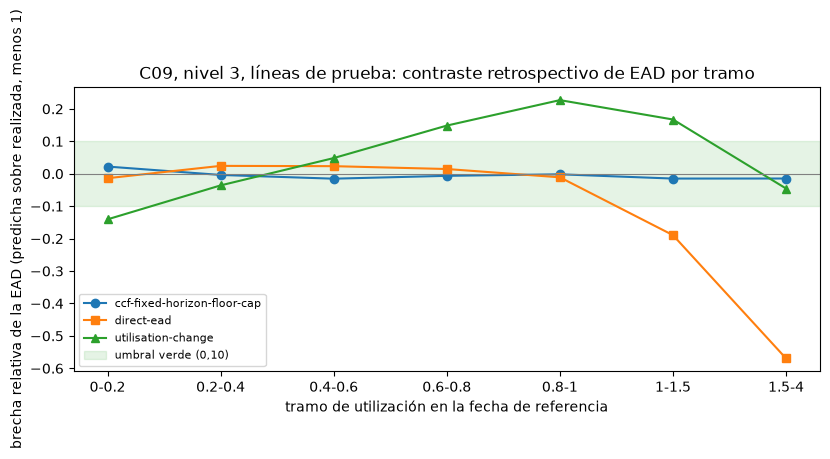

In [7]:
# Dibujar la brecha relativa por tramo de utilización para tres de los modelos
fig, ax = plt.subplots(figsize=(8.4, 3.8))
labels = [f"{lo:g}-{hi:g}" for lo, hi in zip(edges[:-1], edges[1:])]
for model_id, marker in zip(three, ("o", "s", "^")):
    bands = results[model_id].extras["bands"]
    gaps = [band["relative_gap"] for band in bands]
    ax.plot(range(len(gaps)), gaps, marker=marker, label=model_id)
    worst = max(bands, key=lambda band: abs(band["relative_gap"] or 0.0))
    edge = f"[{worst['lower']}, {worst['upper']})"
    print(f"{model_id:30s} peor tramo {edge} brecha relativa {worst['relative_gap']:+.3f}")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.axhspan(-0.10, 0.10, color="tab:green", alpha=0.12, label="umbral verde (0,10)")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_xlabel("tramo de utilización en la fecha de referencia")
ax.set_ylabel("brecha relativa de la EAD (predicha sobre realizada, menos 1)")
ax.set_title("C09, nivel 3, líneas de prueba: contraste retrospectivo de EAD por tramo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los tramos están en utilización a la fecha de referencia, así que los tramos de la derecha reúnen líneas que ya estaban totalmente giradas o sobre su límite. El modelo directo falla ahí: predice una parte del límite y no puede superarlo, mientras las líneas sobre su límite terminan por encima, de modo que su brecha en el tramo más alto es grande y negativa. El modelo de factor se mantiene dentro de la banda verde casi en todas partes, porque aplica una parte constante al monto no utilizado que tenga cada línea, y el modelo de cambio de utilización sale de la banda en los tramos donde el saldo ya está cerca del límite. Una métrica por modelo nombraría al modelo que falla; la figura dice en qué líneas falla.

### Paso 4: las tres pruebas de LGD sobre un ejemplo pequeño, a mano

Las pruebas de LGD del motor toman la LGD realizada y la predicha de cada préstamo. La celda inventa doce préstamos (valores realizados y predichos escritos) para que cada intermedio sea visible, y calcula a mano lo que calculan la primera y la tercera prueba:

- `lgd_calibration_by_segment`: una prueba t pareada de la brecha $d_i = \text{realizada}_i - \text{predicha}_i$, $t = \bar d / (s_d / \sqrt{N})$ con $N - 1$ grados de libertad y un valor p de dos colas; la métrica es $\bar d$; la luz es verde cuando el valor p es al menos 0.05, ámbar desde 0.01 y rojo bajo eso.
- `lgd_discrimination`: la correlación de rangos de Spearman $\rho$ de la LGD predicha y la realizada, que es la correlación de Pearson de los rangos (empates por rango promedio); la luz es verde cuando $\rho \ge 0.30$, ámbar desde 0.10, rojo bajo eso, un umbral de Contraste, porque el poder de ordenamiento de la LGD es modesto en la literatura.

(Las reglas y umbrales son los de los docstrings de las dos funciones.) El valor p del estadístico t viene del motor, que usa la distribución t; el notebook calcula el estadístico por su cuenta.

In [8]:
# Doce préstamos inventados: t pareado y Spearman a mano, y luego las dos pruebas del motor
real = np.array([0.55, 0.70, 0.40, 0.90, 0.62, 0.35, 0.80, 0.58, 0.66, 0.48, 0.75, 0.52])
pred = np.array([0.50, 0.60, 0.45, 0.70, 0.61, 0.40, 0.65, 0.55, 0.52, 0.51, 0.62, 0.47])
d = real - pred
n = d.size
mean_d, sd_d = d.mean(), d.std(ddof=1)
se = sd_d / np.sqrt(n)
print(f"N={n} | brecha media {mean_d:.4f} | desviación estándar {sd_d:.4f}")
print(f"error estándar {se:.4f} | t = {mean_d / se:.4f}")
rank = np.argsort(np.argsort(real)) + 1.0, np.argsort(np.argsort(pred)) + 1.0
rho = np.corrcoef(rank[0], rank[1])[0, 1]
print(f"rangos de los valores realizados: {rank[0].astype(int).tolist()}")
print(f"rangos de los valores predichos: {rank[1].astype(int).tolist()} | Spearman a mano = {rho:.4f}")

by_segment = tests.lgd_calibration_by_segment(real, pred, segment="invented")
rank_test = tests.lgd_discrimination(real, pred, segment="invented")
low, high = by_segment.extras["ci_low"], by_segment.extras["ci_high"]
sig = light[by_segment.light.value]
print(f"lgd_calibration_by_segment: t={by_segment.statistic:.4f} p={by_segment.p_value:.4f} {sig}")
print(f"intervalo de 95% de la brecha media: ({low:.4f}, {high:.4f})")
print(f"lgd_discrimination: rho={rank_test.statistic:.4f} p={rank_test.p_value:.4g} {light[rank_test.light.value]}")

N=12 | brecha media 0.0608 | desviación estándar 0.0834
error estándar 0.0241 | t = 2.5271
rangos de los valores realizados: [5, 9, 2, 12, 7, 1, 11, 6, 8, 3, 10, 4]
rangos de los valores predichos: [4, 8, 2, 12, 9, 1, 11, 7, 6, 5, 10, 3] | Spearman a mano = 0.9441
lgd_calibration_by_segment: t=2.5271 p=0.0281 ámbar
intervalo de 95% de la brecha media: (0.0079, 0.1138)
lgd_discrimination: rho=0.9441 p=3.927e-06 verde


### Paso 5: los mismos préstamos en el tiempo

`lgd_calibration_over_time(realised, predicted, period)` corre la prueba t pareada dentro de cada período (un año de incumplimiento o un índice de cohorte), conserva los períodos con al menos dos observaciones y dispersión no nula, y los combina:

$$\text{estadístico} = \max_k |t_k|, \qquad p = \min\big(1,\; K\,\min_k p_k\big), \qquad \text{métrica} = \max_k |\bar d_k|$$

con $K$ el número de períodos probados (un ajuste de Bonferroni, para que mirar varios períodos no infle la probabilidad de una falsa alarma). Un período con dispersión nula y una brecha distinta de cero deja la luz en rojo. La celda asigna los doce préstamos a tres años de cuatro, corre la prueba y comprueba el ajuste desde las filas por período que devuelve el motor.

In [9]:
# Correr lgd_calibration_over_time sobre los doce préstamos en tres años y comprobar Bonferroni con sus filas
period = np.repeat([2019, 2020, 2021], 4)
over_time = tests.lgd_calibration_over_time(real, pred, period, model_id="invented")
for row in over_time.extras["periods"]:
    print(f"período {row['period']}: n={row['n']} brecha media {row['mean_gap']:.4f} t={row['t']:.4f} p={row['p']:.4f}")
k = over_time.extras["n_periods_tested"]
p_min = min(r["p"] for r in over_time.extras["periods"])
print(f"K={k} | estadístico (|t| máximo) {over_time.statistic:.4f} | p = min(1, K * min p) = {min(1.0, k * p_min):.4f}")
print(f"p del motor {over_time.p_value:.4f} | {light[over_time.light.value]}")

período 2019: n=4 brecha media 0.0750 t=1.4412 p=0.2452
período 2020: n=4 brecha media 0.0350 t=0.8347 p=0.4651
período 2021: n=4 brecha media 0.0725 t=1.8280 p=0.1650
K=3 | estadístico (|t| máximo) 1.8280 | p = min(1, K * min p) = 0.4950
p del motor 0.4950 | verde


### Paso 6: la batería de LGD versionada de C08, 2014-19

La variante de C08 guarda las filas de pruebas del motor para cada peldaño de la escalera: calibración por segmento (toda la cohorte es el segmento), discriminación, y calibración en el tiempo. La prueba en el tiempo de una variante por corte corre sobre todos los incumplimientos posteriores al corte de entrenamiento, así que sus períodos son los años de incumplimiento y su número de préstamos es mayor que el de la cohorte; la celda comprueba esa cifra. Luego imprime, para los seis peldaños, la brecha media con su valor p y luz, la correlación de Spearman con su luz y el estadístico en el tiempo, y verifica el ajuste de Bonferroni desde las filas por período guardadas del peldaño de logit fraccional.

In [10]:
# Imprimir la batería versionada de los seis peldaños (2014-19) y la aritmética de Bonferroni de sus filas
rows = {(t["model_id"], t["test_id"].split(".")[1]): t for t in c08["tests"] if t["model_id"]}
n_cohort = c08["outputs"]["lgd_distribution"]["n"]
n_next = c08_next["outputs"]["lgd_distribution"]["n"]
over = rows[("L2-fractional-logit", "lgd_calibration_over_time")]
total = n_cohort + n_next
print(f"préstamos en 2014-19: {n_cohort:,} | en 2020-23: {n_next:,} | suma: {total:,}")
print(f"préstamos en la prueba en el tiempo: {over['n']:,}")
short = {"L1-ols": "OLS", "L2-fractional-logit": "logit fraccional", "L3-beta": "beta", "L4-hurdle": "dos etapas",
         "L5-gradient-boosted": "árboles potenciados", "L6-tobit": "Tobit"}
lt = "semáforo"
print(f"{'peldaño':18s} {'brecha':>9s} {'p':>10s} {lt:>8s} | {'Spearman':>8s} {lt:>8s} | {'max |t|':>8s} {lt:>8s}")
names = ("lgd_calibration_by_segment", "lgd_discrimination", "lgd_calibration_over_time")
for rung in short:
    a, b_, c = (rows[(rung, name)] for name in names)
    left = f"{short[rung]:18s} {a['metric']:9.4f} {a['p_value']:10.2e} {light[a['light']]:>8s}"
    middle = f"{b_['metric']:8.4f} {light[b_['light']]:>8s}"
    print(left, "|", middle, "|", f"{c['statistic']:8.3f} {light[c['light']]:>8s}")
periods = over["extras"]["periods"]
p_min = min(r["p"] for r in periods)
print(f"logit fraccional: K={len(periods)} | min p = {p_min:.3e} | K * min p = {len(periods) * p_min:.3e}")
print(f"p versionado = {over['p_value']:.3e}")

préstamos en 2014-19: 36,481 | en 2020-23: 13,930 | suma: 50,411
préstamos en la prueba en el tiempo: 50,411
peldaño               brecha          p semáforo | Spearman semáforo |  max |t| semáforo
OLS                   0.0058   8.46e-05     rojo |   0.4390    verde |    7.066     rojo
logit fraccional      0.0164   4.37e-28     rojo |   0.4399    verde |   10.799     rojo
beta                  0.0138   2.88e-20     rojo |   0.4257    verde |    9.555     rojo
dos etapas            0.0165   1.45e-28     rojo |   0.4405    verde |   10.845     rojo
árboles potenciados    0.0300   1.85e-96     rojo |   0.5139    verde |   17.831     rojo
Tobit                 0.0167   1.88e-29     rojo |   0.4376    verde |    9.229     rojo
logit fraccional: K=10 | min p = 4.991e-27 | K * min p = 4.991e-26
p versionado = 4.991e-26


La brecha media es positiva para todos los peldaños y el semáforo de calibración es rojo para todos, mientras la correlación de Spearman está sobre el umbral verde para todos: los modelos ordenan aceptablemente los préstamos y ponen su nivel demasiado bajo. El semáforo lo fija el valor p, no el tamaño de la brecha: con 36.481 préstamos una brecha muy inferior a un punto porcentual ya es roja. La última figura muestra la brecha por año de incumplimiento del peldaño de logit fraccional, que es donde la prueba en el tiempo encuentra su mayor t.

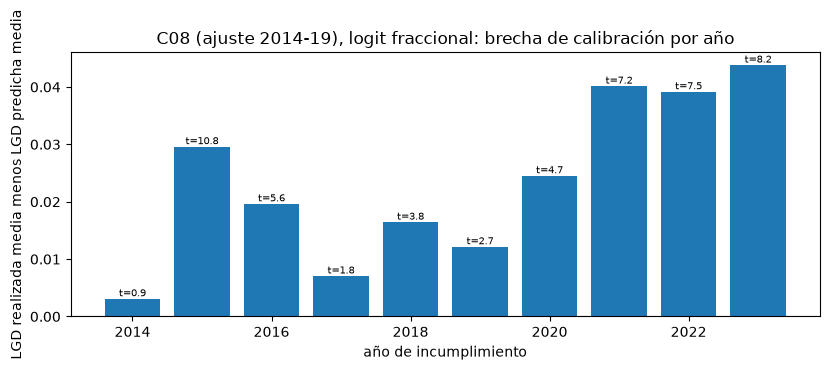

In [11]:
# Dibujar la brecha media por año de incumplimiento del peldaño de logit fraccional, con el estadístico t de cada año
fig, ax = plt.subplots(figsize=(8.4, 3.6))
years = [r["period"] for r in periods]
ax.bar(years, [r["mean_gap"] for r in periods], color="tab:blue")
for r in periods:
    ax.annotate(f"t={r['t']:.1f}", (r["period"], r["mean_gap"]), ha="center", va="bottom", fontsize=7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("año de incumplimiento")
ax.set_ylabel("LGD realizada media menos LGD predicha media")
ax.set_title("C08 (ajuste 2014-19), logit fraccional: brecha de calibración por año")
fig.tight_layout()
plt.show()

## Resultados

**Respuesta:** Contrastado sobre líneas que los modelos no han visto, el modelo de factor con piso y tope queda a menos de 0,0221 de la EAD realizada en todo tramo (verde), el modelo de cambio de utilización queda en ámbar con 0,2270 y peor en el tramo de 0,8 a 1,0 (+0,227), y el modelo directo queda en rojo con 0,5695 y peor en el tramo de 1,5 a 4,0 (-0,570); evaluar las mismas predicciones en tres tramos gruesos baja la métrica del modelo directo a 0,4655 y la del modelo de factor a 0,0148. En la cohorte 2014-19 de C08 las pruebas del motor dan semáforo rojo de calibración a los seis peldaños (brechas medias de 0,0058 a 0,0300) y semáforo verde de discriminación a todos (Spearman de 0,4257 a 0,5139): los modelos ordenan los préstamos y ponen el nivel demasiado bajo.

- **El contraste retrospectivo es una fórmula trabajada.** En las seis facilidades inventadas las brechas por tramo son -0,0222, -0,1429 y 0,0843, de modo que la métrica es 0,1429 (ámbar) y la brecha relativa del total es solo -0,0032: un total puede verse bien mientras un tramo está mal. El motor devuelve los mismos números.
- **Los modelos fallan en lugares distintos.** En las líneas de prueba generadas los modelos de factor de horizonte fijo están en verde (0,0221 a 0,0416), el de horizonte variable también (0,0350), el diseño de cohorte en ámbar con 0,2462, el modelo de cambio de utilización en ámbar con 0,2270 y el modelo directo de EAD en rojo con 0,5695, por las líneas sobre su límite que no puede predecir. Las métricas versionadas sobre veinte replicaciones son del mismo orden, por ejemplo 0,2033 para el diseño de cohorte y 0,5719 para el modelo directo.
- **Los bordes de tramo son parte del resultado.** En la grilla gruesa el modelo de factor obtiene 0,0148 frente a 0,0221 en la fina y el modelo directo 0,4655 frente a 0,5695, mientras el modelo de cambio de utilización conserva 0,2270 porque su peor tramo es un tramo de ambas grillas.
- **Toda prueba de LGD puede calcularse a mano.** En los doce préstamos inventados la brecha media es 0,0608 con una desviación estándar de 0,0834 y un error estándar de 0,0241, de modo que t = 2,5271 y el valor p del motor es 0,0281 (ámbar); la correlación de Spearman es 0,9441 a mano y con el motor (verde).
- **La prueba en el tiempo es un máximo con ajuste de Bonferroni.** Con tres períodos el mayor |t| es 1,8280 y el valor p ajustado 0,4950, que es tres veces el menor valor p de un período.
- **C08, 2014-19: la calibración es roja para todo peldaño y la discriminación es verde para todo peldaño.** Las brechas medias van de 0,0058 a 0,0300 con valores p de 8,46e-05 a 1,85e-96, las correlaciones de Spearman de 0,4257 a 0,5139, y los estadísticos en el tiempo de 7,066 a 17,831. El semáforo lo fija el valor p, no el tamaño de la brecha: con 36.481 préstamos una brecha de 0,0058 ya es roja. La prueba en el tiempo cubre 50.411 préstamos, la suma de las cohortes 2014-19 y 2020-23, y su ajuste cuadra con las filas guardadas (K = 10, 10 por 4,991e-27 es el 4,991e-26 versionado).

Lo que el notebook no hace: no recalcula las filas de LGD por préstamo de C08, que no se versionan; la batería de C08 se lee como versionada. Las líneas generadas son sintéticas y los préstamos y facilidades inventados solo muestran la aritmética. El notebook siguiente pone estos resultados junto a la evidencia comparada.

## Resumen

- Un modelo de EAD se contrasta retrospectivamente en moneda por tramo de utilización: las brechas por tramo, su tamaño relativo, y la mayor de ellas como métrica, con un umbral verde en 0,10 y uno rojo en 0,25 que son propios de Contraste. Los bordes de tramo son un argumento de la prueba, y bordes más gruesos solo pueden bajar la métrica.
- Ajustado y contrastado sobre líneas generadas, el modelo de factor pasa en todos los tramos, el de cambio de utilización sale de la banda donde el saldo está cerca del límite, y el directo falla en las líneas sobre su límite porque no puede predecir por encima de él.
- Las pruebas de LGD son un t pareado sobre la brecha media, una correlación de Spearman contra umbrales fijos y un t pareado en el tiempo con ajuste de Bonferroni; cada una puede calcularse a mano en un ejemplo pequeño.
- En C08 el semáforo de calibración es rojo para todos los peldaños mientras la discriminación es verde: calibración y orden son preguntas distintas, y la batería hace ambas.

**Qué probar después.** Cambia las EAD predichas del paso 1 para que un tramo pase de verde a ámbar y luego a rojo, y cambia los bordes gruesos del paso 2 para ver moverse la métrica; luego continúa con el notebook 07, que pone los resultados de C08 y C09 junto a la evidencia comparada de la literatura.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: el documento detrás de las pruebas de PD del tema 01; las pruebas de LGD y EAD de este notebook siguen los docstrings y umbrales propios del motor. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Spearman, C. (1904), The proof and measurement of association between two things, American Journal of Psychology 15(1). https://doi.org/10.2307/1412159
- La documentación del propio motor de `ead_backtest_by_band`, `lgd_calibration_by_segment`, `lgd_calibration_over_time` y `lgd_discrimination` (versión 0.8.1), que enuncia cada regla y umbral citado arriba.
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09), `data/derived/C09/level-3.json` y `data/derived/C08/dc-2014-19.json`.